# Seuil optimal par Machine Learning : Régression linéaire et Random Forest

**Idée :** au lieu de calculer le seuil avec une formule (Otsu), on **apprend** à le prédire à partir de l'histogramme de l'image.

| Étape | Contenu |
|---|---|
| 1 | Générer beaucoup d'images avec leur **masque idéal** (vérité terrain) |
| 2 | Calculer pour chaque image le **seuil optimal T\*** (celui qui donne le meilleur IoU avec le masque) |
| 3 | Extraire des **caractéristiques** de l'histogramme (moyenne, écart-type, percentiles, seuil d'Otsu...) |
| 4 | Entraîner **Régression linéaire** et **Random Forest** : caractéristiques → T\* |
| 5 | Comparer avec seuil fixe et Otsu |

Le **IoU** mesure la qualité de la segmentation (1 = parfait) : intersection / union entre le masque trouvé et le masque idéal.

In [16]:
import numpy as np, cv2, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, r2_score

rng = np.random.default_rng(0)

## 1. Création du jeu de données

Chaque image : un fond, des objets plus clairs, avec des conditions **variables** (luminosité, contraste, bruit, flou, taille des objets, léger gradient d'éclairage). C'est cette variété qui fait échouer un seuil fixe, et parfois Otsu.

In [2]:
def make_sample(size=128):
    mask = np.zeros((size, size), np.uint8)
    for _ in range(rng.integers(1, 4)):
        x, y = rng.integers(10, size - 10, 2)
        s = int(rng.integers(5, 35))                      # taille variable des objets
        if rng.random() < 0.5:
            cv2.circle(mask, (int(x), int(y)), s, 1, -1)
        else:
            cv2.rectangle(mask, (int(x), int(y)), (int(min(x + 1.5 * s, size - 1)), int(min(y + s, size - 1))), 1, -1)
    bg = rng.uniform(10, 160)                             # luminosité du fond
    contrast = rng.uniform(20, 90)                        # contraste objet / fond
    img = bg + contrast * mask
    if rng.random() < 0.5:                                # gradient d'éclairage léger
        img = img + rng.uniform(-20, 20) * np.linspace(-1, 1, size)[None, :]
    img = cv2.GaussianBlur(img.astype(np.float32), (0, 0), rng.uniform(0.5, 2))
    img = img + rng.normal(0, rng.uniform(2, 14), img.shape)  # bruit
    return np.clip(img, 0, 255).astype(np.uint8), mask

def iou_curve(img, mask):
    """IoU obtenu pour chaque seuil T = 0..255 (pixel > T => objet)."""
    ho = np.bincount(img[mask == 1], minlength=256)
    hb = np.bincount(img[mask == 0], minlength=256)
    co, cb = np.cumsum(ho), np.cumsum(hb)
    tp = co[-1] - co
    fp = cb[-1] - cb
    fn = co
    return tp / np.maximum(tp + fp + fn, 1)

def best_threshold(curve):
    """Seuil optimal T* : milieu de la zone où l'IoU est maximal."""
    idx = np.where(curve >= curve.max() - 1e-3)[0]
    return int(idx.mean())

def features(img):
    x = img.ravel().astype(np.float64)
    p5, p25, p50, p75, p95 = np.percentile(x, [5, 25, 50, 75, 95])
    otsu, _ = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    skew = ((x - x.mean()) ** 3).mean() / (x.std() ** 3 + 1e-9)
    return [x.mean(), x.std(), x.min(), x.max(), p5, p25, p50, p75, p95, otsu, skew]

FEATURES = ["moyenne", "écart-type", "min", "max", "p5", "p25", "p50", "p75", "p95", "otsu", "asymétrie"]

N = 2000
images, masks = zip(*[make_sample() for _ in range(N)])
curves = np.array([iou_curve(i, m) for i, m in zip(images, masks)])
y = np.array([best_threshold(c) for c in curves])
X = np.array([features(i) for i in images])

print("Images :", N, "| caractéristiques par image :", X.shape[1])
print("Seuil optimal T* : min", y.min(), "| max", y.max(), "| moyenne", round(y.mean(), 1))

Images : 2000 | caractéristiques par image : 11
Seuil optimal T* : min 21 | max 205 | moyenne 114.1


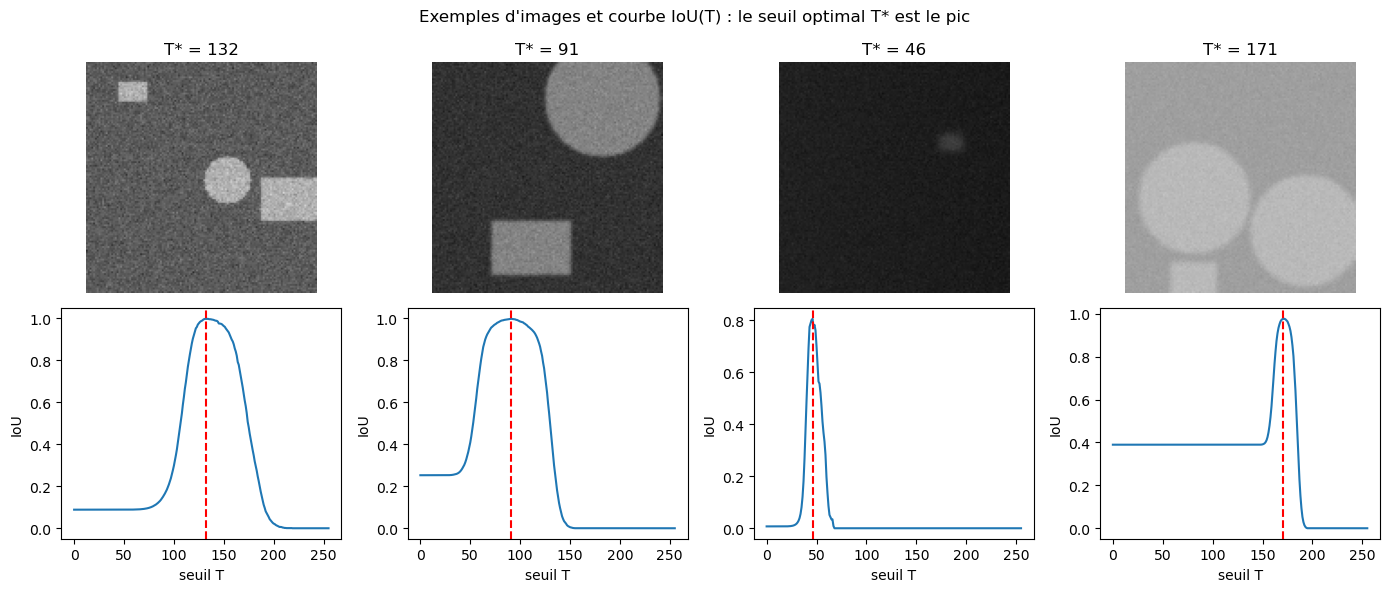

In [3]:
fig, ax = plt.subplots(2, 4, figsize=(14, 6))
for k in range(4):
    ax[0, k].imshow(images[k], cmap="gray", vmin=0, vmax=255); ax[0, k].axis("off")
    ax[0, k].set_title(f"T* = {y[k]}")
    ax[1, k].plot(curves[k]); ax[1, k].axvline(y[k], color="red", ls="--")
    ax[1, k].set_xlabel("seuil T"); ax[1, k].set_ylabel("IoU")
plt.suptitle("Exemples d'images et courbe IoU(T) : le seuil optimal T* est le pic")
plt.tight_layout(); plt.show()

## 2. Entraînement

On sépare les données : 80 % pour apprendre (*train*), 20 % pour tester (*test*) sur des images jamais vues.

In [4]:
idx = np.arange(N)
i_train, i_test = train_test_split(idx, test_size=0.2, random_state=0)
X_train, X_test, y_train, y_test = X[i_train], X[i_test], y[i_train], y[i_test]

lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1).fit(X_train, y_train)

pred_lin = np.clip(lin.predict(X_test), 0, 255)
pred_rf = np.clip(rf.predict(X_test), 0, 255)
pred_otsu = X_test[:, FEATURES.index("otsu")]

res = pd.DataFrame({
    "MAE (erreur moyenne sur T)": [mean_absolute_error(y_test, p) for p in (pred_otsu, pred_lin, pred_rf)],
    "R²": [r2_score(y_test, p) for p in (pred_otsu, pred_lin, pred_rf)],
}, index=["Otsu", "Régression linéaire", "Random Forest"]).round(3)
res

,MAE (erreur moyenne sur T),R²
Otsu,7.815,0.922
Régression linéaire,2.865,0.992
Random Forest,3.125,0.991


**MAE** : écart moyen (en niveaux de gris) entre le seuil prédit et le seuil optimal. Plus petit = mieux.
**R²** : part de variance expliquée (1 = parfait).

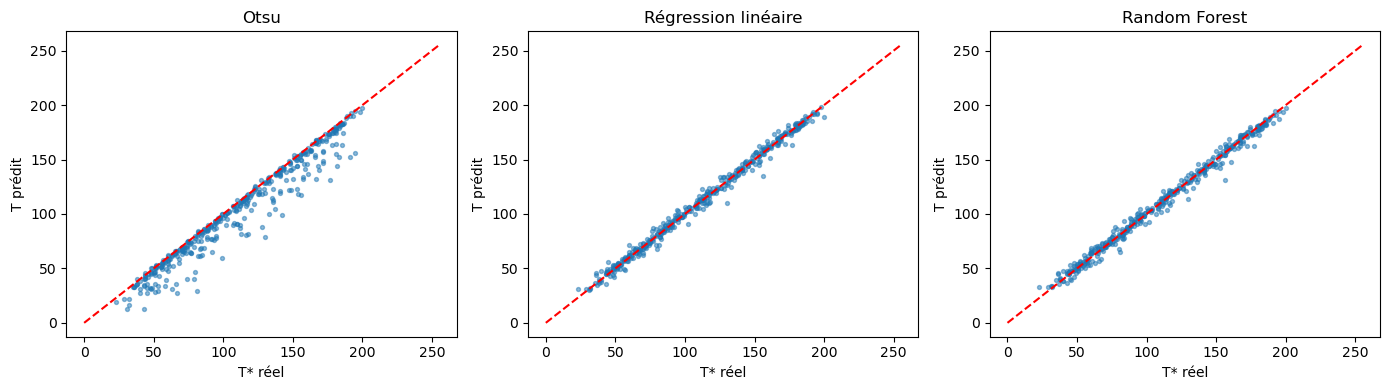

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (nom, p) in zip(ax, [("Otsu", pred_otsu), ("Régression linéaire", pred_lin), ("Random Forest", pred_rf)]):
    a.scatter(y_test, p, s=8, alpha=0.5)
    a.plot([0, 255], [0, 255], "r--")
    a.set_xlabel("T* réel"); a.set_ylabel("T prédit"); a.set_title(nom)
plt.tight_layout(); plt.show()

## 3. Qualité réelle de la segmentation (IoU)

Ce qui compte vraiment : quel IoU obtient-on en appliquant le seuil prédit ? On compare avec un seuil fixe (127), Otsu, et le seuil parfait (maximum possible).

In [6]:
def mean_iou(thresholds):
    return np.mean([curves[i][int(round(t))] for i, t in zip(i_test, thresholds)])

tableau = pd.DataFrame({"IoU moyen (test)": [
    mean_iou(np.full(len(i_test), 127)),
    mean_iou(pred_otsu),
    mean_iou(pred_lin),
    mean_iou(pred_rf),
    mean_iou(y_test),
]}, index=["Seuil fixe 127", "Otsu", "Régression linéaire", "Random Forest", "Seuil optimal (maximum)"]).round(3)
tableau

,IoU moyen (test)
Seuil fixe 127,0.279
Otsu,0.741
Régression linéaire,0.848
Random Forest,0.843
Seuil optimal (maximum),0.872


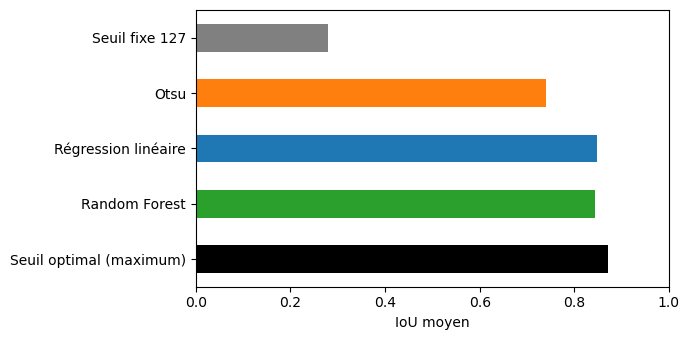

In [7]:
tableau["IoU moyen (test)"].plot.barh(figsize=(7, 3.5), color=["gray", "tab:orange", "tab:blue", "tab:green", "black"])
plt.xlim(0, 1); plt.xlabel("IoU moyen"); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

## 4. Quelles caractéristiques comptent ?

Le Random Forest indique l'importance de chaque caractéristique ; la régression linéaire donne un coefficient (sur variables standardisées).

In [8]:
imp = pd.DataFrame({
    "importance RF": rf.feature_importances_,
    "coefficient (linéaire)": lin[-1].coef_,
}, index=FEATURES).round(3).sort_values("importance RF", ascending=False)
imp

,importance RF,coefficient (linéaire)
moyenne,0.840,-95.991
p50,0.072,68.814
otsu,0.044,-2.720
max,0.030,21.058
p25,0.007,11.326
p75,0.002,2.853
écart-type,0.001,11.160
min,0.001,0.965
p5,0.001,44.949
p95,0.001,-6.660


## 5. Utilisation sur une image

On prédit le seuil avec le Random Forest, puis on segmente. Pour votre propre image : mettez son chemin dans `IMAGE_PATH`.

Seuil Random Forest = 160 | Régression linéaire = 173 | Otsu = 107


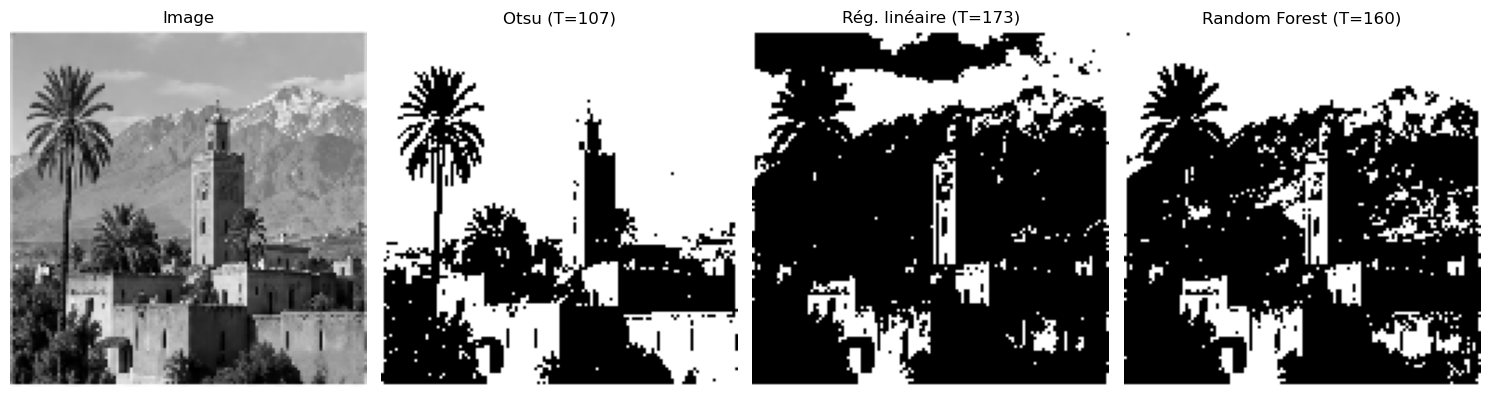

In [10]:
IMAGE_PATH = "image.png"     # ex: "mon_image.jpg"

if IMAGE_PATH:
    test_img = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
    test_img = cv2.resize(test_img, (128, 128))
    test_mask = None
else:
    k = i_test[0]
    test_img, test_mask = images[k], masks[k]

f = np.array(features(test_img)).reshape(1, -1)
T_rf = float(np.clip(rf.predict(f)[0], 0, 255))
T_lin = float(np.clip(lin.predict(f)[0], 0, 255))
T_otsu = f[0, FEATURES.index("otsu")]
print(f"Seuil Random Forest = {T_rf:.0f} | Régression linéaire = {T_lin:.0f} | Otsu = {T_otsu:.0f}")

fig, ax = plt.subplots(1, 4, figsize=(15, 4))
ax[0].imshow(test_img, cmap="gray"); ax[0].set_title("Image")
for a, (nom, T) in zip(ax[1:], [("Otsu", T_otsu), ("Rég. linéaire", T_lin), ("Random Forest", T_rf)]):
    m = (test_img > T)
    t = f"{nom} (T={T:.0f})"
    if test_mask is not None:
        t += f"\nIoU = {((m & (test_mask == 1)).sum() / (m | (test_mask == 1)).sum()):.3f}"
    a.imshow(m, cmap="gray"); a.set_title(t)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## Conclusion et limites

- Le modèle prédit un seuil à partir de la **forme de l'histogramme** ; le Random Forest capture des relations non linéaires que la régression linéaire ne peut pas modéliser.
- Les résultats ci-dessus viennent d'images **synthétiques** : le modèle est valable pour ce type d'images.
- Pour une application réelle (vos images de produits), il faut un jeu d'images **avec masques annotés** : on remplace `make_sample()` par la lecture de vos images et masques, le reste du notebook ne change pas.
- Un seul seuil global ne peut pas corriger un éclairage très inégal : dans ce cas il faut CLAHE ou un seuillage adaptatif avant.